# Data exploration with pandas and sklearn

## The goal of this homework is to discover structure in an unlabeled dataset. The observations in this dataset belong to several different clusters. The specific goal is to identify how many clusters there are and to which cluster each point belongs.

## Question 1 (5 points). Load the dataset into a pandas dataframe. Each row represents a single observation; the values in the columns are numeric features recorded for that observation (in other words, this is a 'tidy' dataset). How many rows and columns are there? What is the dimension of this dataset? In other words, how many different features are there for each observation?

In [2]:
# you could start with something like this...
import matplotlib.pyplot as plt # for plotting
import pandas as pd # pandas

datafile = 'data/dataset.csv'

df = pd.read_csv(datafile) # df for dataframe but you can call it whatever you like

print(df.head()) # make sure the data looks correct

n_rows, n_cols = df.shape # get number of rows and number of columns 

print(f'The dataset has {n_rows} rows and {n_cols} columns.') 



     dim1    dim2    dim3    dim4    dim5    dim6    dim7    dim8    dim9  \
0   3.371  16.877  15.345   8.080   8.510  14.404   5.904  -0.368  11.604   
1  11.765  18.278   9.311   4.095  13.699   1.487  16.061   7.425   5.981   
2   3.966   2.498   9.110  12.823  -0.337  15.771   5.326  18.289  12.466   
3  11.498  16.627  10.134   3.632  13.124   1.083  17.141   8.624   6.133   
4  12.262  18.252  10.158   4.073  14.841   2.451  15.654   8.131   5.142   

   dim10  
0  3.321  
1 -0.338  
2  9.633  
3  0.015  
4 -0.079  
The dataset has 496 rows and 10 columns.


## Question 2 (5 points). Make a scatter plot of `dim1` versus `dim2`, ie the first column versus the second one. How many clusters do you see in this plot?

I see 3 clusters in this plot.


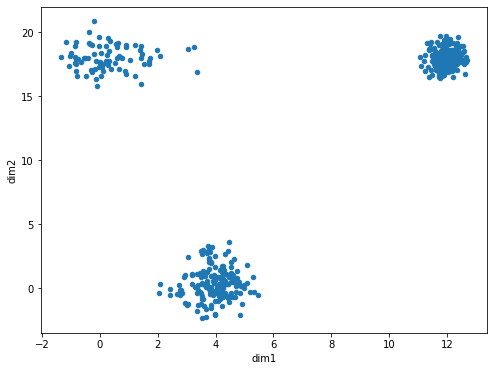

In [3]:
# You could use either 
#
#plt.scatter(xvals, yvals) #with appropriate choices for xvals and yvals (see lecture 10 for examples) 
#
# or
#
#df.plot.scatter(...) #filling in the "..."
#
# recall that df['dim1'] returns the single column of values in the 'dim1' column
#

df.plot.scatter(x='dim1', y='dim2', figsize=(8,6)) 

print(f'I see 3 clusters in this plot.') 

## Question 3 (15 points). Perform principal components analysis (PCA) on the dataset, following along with the example in the lectures10and11 notebook. What fraction of the variation in the dataset is captured by the first two components? Make a plot of the first component against the second component. Now how many clusters do you see in the data? (2 points extra credit if you standardize the data first using `sklearn.preprocessing.StandardScaler`; see the lectures10and11 notebook for an example of how to do that.)

The fraction of the total variance explained by each component is: [0.71764809 0.14764088]
The total explained variance is : 0.8652889715229933
I see 5 clusters in this plot.


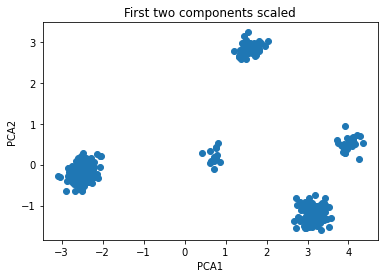

In [4]:

# standardize the data first 
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler
scaler.fit(df) 
df_scaled = scaler.transform(df)


# start by importing the PCA class
from sklearn.decomposition import PCA

# 1. create and configure the model (call it "pca")

pca = PCA(n_components=2)

# 2. fit the model to the data (use pca.fit(...) )

pca.fit(df_scaled)

# 3. look at the model's explained_variance_ratio_ (i.e., pca.explained_variance_ratio_ where pca
#    is what you called the PCA object) to see how much variance the top two components capture.

print('The fraction of the total variance explained by each component is:', pca.explained_variance_ratio_)
print('The total explained variance is :', pca.explained_variance_ratio_.sum())

# 4. transform the data to a new array, call it "X_pca" (use pca.transform(...) )

X_pca = pca.transform(df_scaled)
X_pca.shape


# 5. Plot the first two components, as we did in class.

plt.scatter(X_pca[:,0], X_pca[:,1] )
plt.title('First two components scaled')
plt.xlabel('PCA1')
plt.ylabel('PCA2') 

print(f'I see 5 clusters in this plot.') 


## Question 4 (15 points). Use the KMeans clustering algorithm from scikit-learn to assign each point in the dataset to a cluster. Configure KMeans to find a number of clusters equal to the number that you identified visually in the PCA plot from question 3. What are the sizes of the different clusters (how many points are in each cluster)? Remake the PCA scatter plot (PC1 versus PC2) colored by the cluster labels.

cluster sizes: 0    256
1    128
2     64
3     32
4     16
Name: clusters, dtype: int64


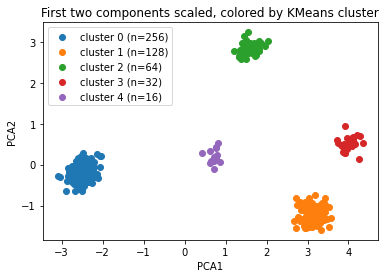

In [5]:
from sklearn.cluster import KMeans

nclust=5 # answer from Question 3

# 1. create a KMeans object, call it kmeans; you'll need to tell it how many clusters to find.
#    Also pass n_init=10 and random_state=0, like this: KMeans(n_clusters=..., n_init=10, random_state=0)
#    (n_init=10 runs KMeans from 10 different random starting points and keeps the best result; with
#    just one start, it occasionally gets stuck with two of the clusters merged together)

kmeans = KMeans(nclust, n_init=10, random_state=0)

# 2. fit the object to the data using kmeans.fit

kmeans.fit(df_scaled)

# 3. Get the list of clusters using kmeans.predict
#    Name the returned array of cluster assignments "clusters"

clusters = kmeans.predict(df_scaled)
clusters 

# To get the cluster sizes, first look at the array of clusters returned by kmeans.predic
#    to see that the different values are integers between 0 and nclust-1, inclusive.

# To get the size of each cluster, you could write a for loop over the different cluster
# numbers, and inside the loop you could count how many elements in clusters array are
# equal to that cluster number. Instead, do it by creating a new column in the dataframe 
# containing the cluster assignments, and using the pandas method value_counts:

df['clusters'] = clusters # create a new column in the dataframe with the KMeans cluster assignments

# NOTE: this adds a new 'clusters' column to df, so df no longer contains just +the original data!
# If you go back and re-run any earlier cells (e.g. the PCA in Question 3), first re-run the cell in
# Question 1 that reads the data from the file, so the cluster assignments don't sneak into the
# analysis as an extra feature.

print('cluster sizes:', df['clusters'].value_counts()) # handy built-in counting method for Pandas Series objects

# use this code to remake the PCA plot colored by the kmeans clusters, where "clusters" is the 
#  array returned by the kmeans.predict function  
#plt.scatter( X_pca[:,0], X_pca[:,1], c=clusters )

for k in range(nclust):
    mask = (clusters == k)
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=f'cluster {k} (n={mask.sum()})')

plt.legend()
plt.title('First two components scaled, colored by KMeans cluster')
plt.xlabel('PCA1')
plt.ylabel('PCA2') 
plt.show()


## Question 5 (10 points). Make a 'scatter matrix' plot showing each column of the original dataset plotted against each of the other 9 columns in a big 10x10 array (like we did for the iris dataset in the lectures10and11 notebook). Notice how the number of apparent clusters in the data depends on which pairs of features are being plotted against one another. Color the plots using the kmeans clusters like you did in the previous question.
You could use `pd.plotting.scatter_matrix` or try importing seaborn (`import seaborn as sns`) and use `sns.pairplot`. Or (optional) try both and see which looks nicer. `sns.pairplot` has a `hue` argument that you can use for coloring by passing `hue='clusters'`. (Don't like the pairplot colors? Try also passing `palette='tab10'`.) See the `pd.plotting.scatter_matrix` and `sns.pairplot` examples in the lectures10and11.ipynb jupyter notebook.

(496, 10)


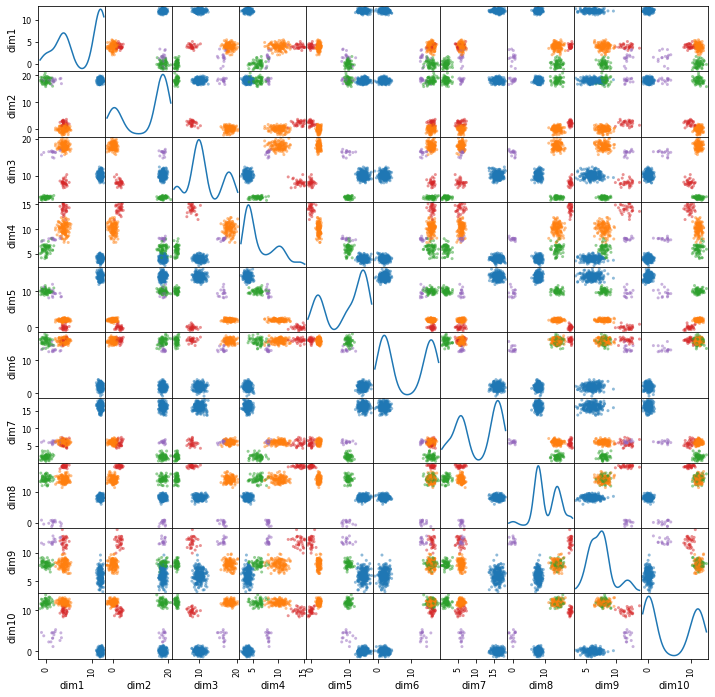

In [6]:
# put your answer here
#
# Note: since we added a 'clusters' column to df in Question 4, pd.plotting.scatter_matrix(df, ...)
# would include it as an 11th row and column. To plot just the 10 original features, drop it first:
# df.drop(columns='clusters'). (sns.pairplot(df, hue='clusters') leaves the hue column out automatically.)


features = df.drop(columns='clusters')
print(features.shape)
pd.plotting.scatter_matrix(features, diagonal='kde', figsize=(12,12), c=[f'C{k}' for k in clusters]);

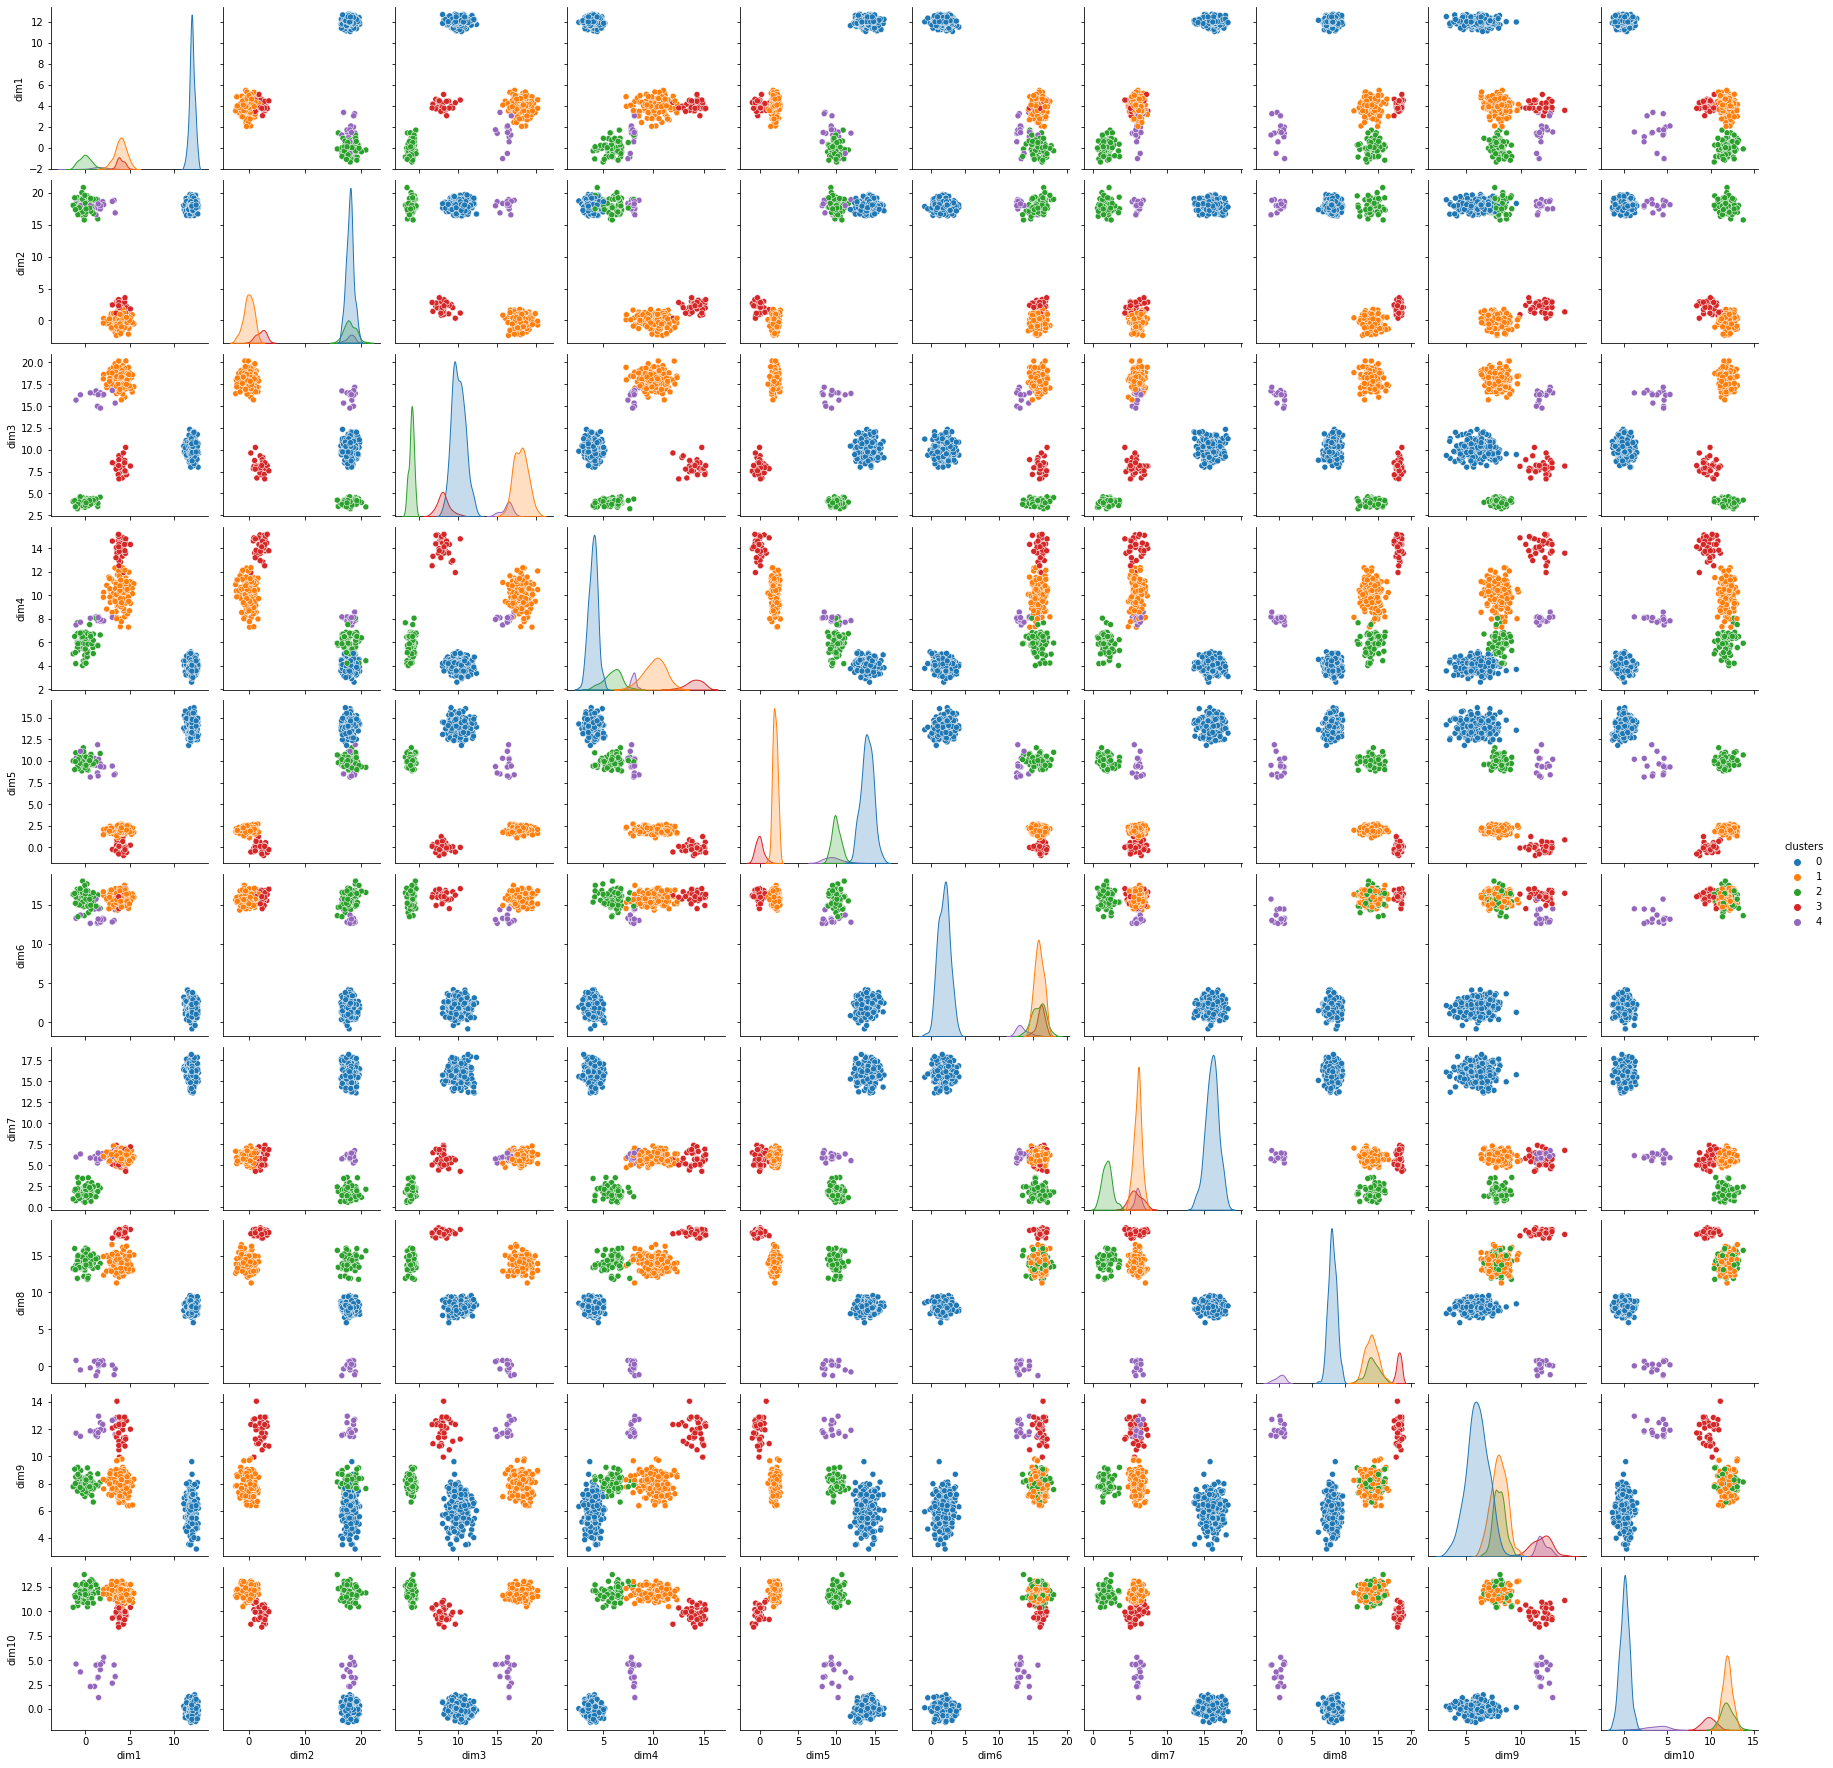

In [7]:
# and maybe also here if you are trying both and comparing...

import seaborn as sns

sns.pairplot(df, hue='clusters', palette='tab10')

## Extra credit (5 points). Use the TSNE algorithm in scikit-learn to project the dataset down into 2 dimensions. How many clusters do you see in the TSNE scatter plot?

/opt/conda/lib/python3.9/site-packages/sklearn/manifold/_t_sne.py:795: FutureWarning: The default initialization in TSNE will change from 'random' to 'pca' in 1.2.
  warnings.warn(
/opt/conda/lib/python3.9/site-packages/sklearn/manifold/_t_sne.py:805: FutureWarning: The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.
  warnings.warn(


I see 5 clusters in this plot.


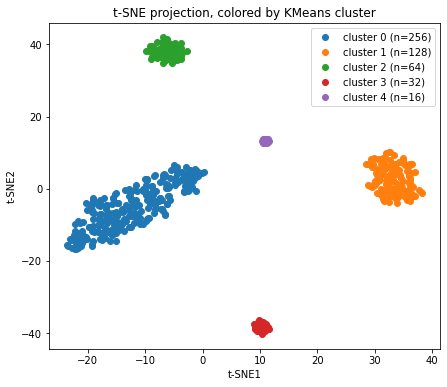

In [7]:
from sklearn.manifold import TSNE

# 1. create the TSNE object, call it tsne. Tell it you want 2 components (ie, a 2D projection),
#    and set random_state=0 so that you get the same picture every time you run it:
#    TSNE(n_components=2, random_state=0)

tsne = TSNE(n_components=2, random_state=0)

# 2. Fit the data to the model and transform to a new array (call it X_tsne) using tsne.fit_transform
#     This combines the fit and transform steps into a single operation.
#     Remember to leave out the 'clusters' column we added to df in Question 4, by passing
#     df.drop(columns='clusters') instead of df; otherwise the cluster assignments become an input feature!

X_tsne = tsne.fit_transform(df_scaled)

# A caution when interpreting t-SNE plots: t-SNE is good at showing which points group together,
# but the sizes of the clusters in the plot, and the distances between clusters, don't mean much.

# Use this matplotlib command to make a scatter plot of the two components, colored by the 
#  kmeans cluster assignments
#plt.scatter( X_tsne[:,0], X_tsne[:,1], c=clusters )

plt.figure(figsize=(7,6))
for k in range(nclust):
    mask = (clusters == k)
    plt.scatter(X_tsne[mask, 0], X_tsne[mask, 1], label=f'cluster {k} (n={mask.sum()})')

plt.legend()
plt.title('t-SNE projection, colored by KMeans cluster')
plt.xlabel('t-SNE1')
plt.ylabel('t-SNE2')
plt.show

print(f'I see 5 clusters in this plot.') 

## Extra credit (3 points). Choose the number of clusters without eyeballing.

So far we've picked the number of clusters by looking at plots. The *silhouette score* is one way to measure how well a clustering fits the data. For each point, it compares the average distance to the other points in its own cluster with the average distance to the points in the nearest *other* cluster. A score close to 1 means the point sits snugly inside a well-separated cluster; a score near 0 means it is on the border between two clusters (and a negative score means it's probably in the wrong cluster). `silhouette_score` from `sklearn.metrics` averages this over all the points.

Run KMeans for each number of clusters k from 2 through 10, compute the silhouette score for each k, and plot the score versus k. Which k scores best? What happens to the score just after that k, and why do you think that happens?

(The silhouette score works best when the clusters are roughly round blobs, as they are here, so it's a useful guide rather than a definitive answer.)

{2: 0.7055474230837936, 3: 0.7957035144386795, 4: 0.8207239928507605, 5: 0.825497207386561, 6: 0.43666628143997277, 7: 0.43486565534438665, 8: 0.27382307641866044, 9: 0.2724750448678782, 10: 0.2720545174551706}


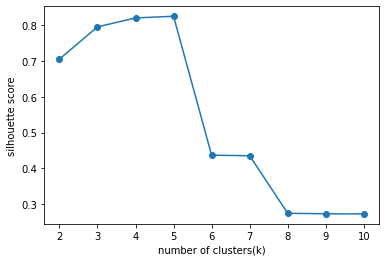

k=5 scores the best. After that, the score drops off because the clusters are not as well separated.


In [ ]:
from sklearn.metrics import silhouette_score

# a fresh copy of the original 10 features, without the 'clusters' column we added in Question 4
X = pd.read_csv(datafile)

k_values = list(range(2, 11))
scores = []
for k in k_values:
    # 1. create a KMeans object with k clusters (use n_init=10 and random_state=0, as in Question 4),
    #    fit it to X, and get the cluster assignments using predict.
    #    Call them "k_clusters" (not "clusters", so we don't overwrite the answer to Question 4)
    km = KMeans(n_clusters=k, n_init=10, random_state=0)
    km.fit(X)
    k_clusters = km.predict(X)
    # 2. compute the silhouette score and add it to the list:
    #scores.append(silhouette_score(X, k_clusters))

    scores.append(silhouette_score(X, k_clusters))

print(dict(zip(k_values, scores)))

# 3. plot the scores versus k
#plt.plot(k_values, scores, marker='o')
#plt.xlabel('number of clusters (k)')
#plt.ylabel('silhouette score')

plt.plot(k_values, scores, marker='o')
plt.xlabel('number of clusters (k)')
plt.ylabel('silhouette score')
plt.show()

print(f'k=5 scores the best. After that, the score drops off because the clusters are not as well separated.') 
